# Topic Modeling
### Bert Sentence Embedding, LDA, and K-means Clustering

#### Concatenate the sentence embeddings with LDA, use an autoencoder to get the latent representation and perform K-means to perform clustering on the data

#### After the sentences have been assigned to their clusters, we can extract the candidate topics for each cluster using tokens of it's sentences

In [ ]:
from google.colab import drive
drive.mount('/content/drive/')


In [ ]:
% cd /content/drive/My Drive/Thesis_colab

In [ ]:
! pip install transformers
! pip install pandas
! pip install torch
! pip install nltk
! pip install gensim
! pip install matplotlib
! pip install umap-learn
! pip install wordcloud
! pip install sklearn
! pip install tqdm
! pip install stop_words
! pip install xlrd
! pip install langdetect
! pip install openpyxl

In [1]:
import nltk
import numpy as np
import statistics
from sklearn.decomposition import PCA
from collections import Counter
import pandas as pd

In [ ]:
nltk.download('punkt')
nltk.download('averaged_perceptron_tagger')

### 1. Reading and preprocessing the data

In [2]:
from utilities.document_preprocessing import preprocess_documents

#### The preprocess_document function reads the sentences from the file and generates tokens from each sentences.

In [5]:
Verbose = False

In [8]:
# Read new data file
file = "data/PMP_Skills_Matching_Pilot_2018_2019_small.xlsx"

ids, sentences, token_lists = preprocess_documents(file, verbose = Verbose)
ids = list (ids)
num_docs = len(ids)

Reading the file
Preprocessing raw texts 

Dropped 0 entries with non english text

 Preprocessing raw texts. Done!


In [9]:
#read the previously processed data
import pandas as pd
data = pd.read_pickle("output/preprocessed_data/use_this_data.pkl")
sentences = list(data['sentences'])
token_lists = list(data['token_list'])
ids = list(data['id'])
num_docs = len(ids)

In [10]:
len(ids)

53

## 2. Topic Modeling

In [12]:
from models.topic_model import Topic_Model

#### The topic_Model class does the follow
- Extract Bert sentence embeddings for all sentences (Local features)
- get topic distribution for each sentence using LDA/LSI
- concatenate both and learn the latent representation using an auto-encoder
- cluster the latent representation into K clusters

In [13]:
# define the numbe of clusters
k = 2

In [31]:
# Define the topic model object
TopicModelObject = Topic_Model(base = 'LSI', k = k, verbose = Verbose, embedding = None, 
                               saved_embedding_dir = "output/preprocessed_data/xlm_embeddings.json", 
                               embedding_batch_size = 100)

In [ ]:
# for Colab
# Define the topic model object
TopicModelObject = Topic_Model(base = 'LSI', k = k, verbose = Verbose, embedding = 'bert', 
                               saved_embedding_dir = "output/embeddings/2020_06_29_20_24_15_bert/bert_embeddings.json", embedding_batch_size = 100)

In [32]:
# Fit the topic model
TopicModelObject.fit(sentences, token_lists)

Getting vector representations for LSI 
Getting vector representations for LSI. Done! 

 LSI Done.


## 3. Analysis on learned features

#### Preprocessing (Dimensionality Reduction) for visualization

Perform Dimensionality reduction on the learned features using the following steps:

1) Merge all the vectors of each employee into one by taking average

2) Assign the class label to each employee based on argmax on label counts.

3) Further compress the average feature vector into 2d/3d space for visualization.

In [33]:
# Getting feature vectors and cluster labels assigned by the model
if TopicModelObject.method == 'LDA' or TopicModelObject.method =='LSI':
    feature_vector = TopicModelObject.vec[TopicModelObject.method]
    # for each sentence, find out the cluster it belongs to
    cluster_label_per_document = np.argmax(np.array(feature_vector), axis=1)
else:
    cluster_label_per_document = np.array(TopicModelObject.cluster_model.labels_)
    feature_vector = TopicModelObject.vec[TopicModelObject.method]
    feature_vector = feature_vector.cpu().numpy()

unique_ids = list(set(ids))
num_employee = len(unique_ids)

In [34]:
# Create place holder for the analysis
averaged_employee_features = pd.DataFrame(None, index=pd.Index(unique_ids, name='Employee id'),
                                          columns=pd.Index(
                                              ['feature_vector', 'cluster', 'feature_vector_2d', 'feature_vector_3d'],
                                              name='Compressed_features'))

In [35]:
# get the indices of all objectives/documents/sentence for each employee (for later use)
employee_objective_indices = dict()
for employee in unique_ids:
    employee_indices = [i for i, e in enumerate(ids) if (ids[i] == employee) ]
    employee_objective_indices[employee] = employee_indices

In [36]:
# 1 & 2 take average of all feature vectors belonging to an employee and assigning cluster label by taking the mode

for employee in unique_ids:
    #get all feature vectors belonging to an employee
    feature_vector_per_employee = feature_vector[employee_objective_indices[employee]]
    # get label for all feature vectors belonging to that employee
    clusters_per_employee = cluster_label_per_document[employee_objective_indices[employee]]  
    
    #take mean of all feature vectors
    averaged_employee_features['feature_vector'][employee] = np.mean(feature_vector_per_employee, axis=0)
    
    # pick the label with most occurance for that employee
    c = Counter(clusters_per_employee)
    averaged_employee_features['cluster'][employee] = c.most_common(1)[0][0]
    
averaged_employee_features

Compressed_features,feature_vector,cluster,feature_vector_2d,feature_vector_3d
Employee id,,,,
*100002,"[0.3367929324477548, -0.10041836091527785]",0,NaN,NaN
*100056,"[1.5774395412835054, -0.09059197387946924]",0,NaN,NaN
*100076,"[0.4940711223046781, 0.32137919287150846]",0,NaN,NaN
*100066,"[1.0568819111903085, -0.25991984610344343]",0,NaN,NaN
*100062,"[0.8940845880007665, 0.3475287101357841]",0,NaN,NaN
*100058,"[0.2933964406167981, -0.161290481181877]",0,NaN,NaN
*100001,"[1.412361959402553, 0.1302434171390417]",0,NaN,NaN
*100059,"[3.986737332848158, -1.670268929024946]",0,NaN,NaN
*100074,"[2.9021917103771715, 0.3692702149809927]",0,NaN,NaN


In [37]:
# 3) doing dimensionality reduction into 2d/3d Space
from sklearn.manifold import TSNE

#todo: find a more permanent solution for this
# panda returns a array of array for the column feature vector. Converting from array of array to 2d array
feature_vector_ = np.stack(averaged_employee_features['feature_vector'].to_numpy())

# reduce dimension of feature vectors into 2
feature_vector_2d = TSNE(n_components=2).fit_transform(feature_vector_)
averaged_employee_features['feature_vector_2d'] = list(feature_vector_2d)

# reduce dimension of feature vectors into 3
feature_vector_3d = TSNE(n_components=3).fit_transform(feature_vector_)
averaged_employee_features['feature_vector_3d'] = list(feature_vector_3d)


averaged_employee_features

Compressed_features,feature_vector,cluster,feature_vector_2d,feature_vector_3d
Employee id,,,,
*100002,"[0.3367929324477548, -0.10041836091527785]",0,"[-121.05728, -0.067729]","[275.20352, -65.63633, 114.97131]"
*100056,"[1.5774395412835054, -0.09059197387946924]",0,"[8.591322, -60.04421]","[-6.5928097, 136.23894, -247.7867]"
*100076,"[0.4940711223046781, 0.32137919287150846]",0,"[59.665195, -58.943794]","[-939.80133, 715.9647, 255.61801]"
*100066,"[1.0568819111903085, -0.25991984610344343]",0,"[-26.276508, -98.29886]","[200.66583, -263.51923, -150.5381]"
*100062,"[0.8940845880007665, 0.3475287101357841]",0,"[-74.78863, -29.043571]","[-108.16023, -153.3904, -159.1292]"
*100058,"[0.2933964406167981, -0.161290481181877]",0,"[40.397816, 80.90643]","[128.17455, -50.97403, -181.03587]"
*100001,"[1.412361959402553, 0.1302434171390417]",0,"[-105.62685, 54.63551]","[-202.8606, 72.71749, -109.30137]"
*100059,"[3.986737332848158, -1.670268929024946]",0,"[-4.9545712, 18.050842]","[1141.5491, -429.8105, -571.74493]"
*100074,"[2.9021917103771715, 0.3692702149809927]",0,"[-1.2915694, 59.439445]","[-48.717316, -387.79617, 187.83792]"


## 4.1 Visualization: Word Cloud

In [38]:
from utilities.visualizations import get_wordcloud
from utilities.utils import generate_n_gram
%matplotlib inline

In [39]:
#Getting indexes of sentences belonging to each cluster
sentence_label_dict = dict()

if TopicModelObject.method == 'LDA' or TopicModelObject.method == 'LSI':
    labels = np.argmax(TopicModelObject.vec[TopicModelObject.base], axis=1)
else:
    labels = TopicModelObject.cluster_model.labels_

for label in set(labels):
    sentence_label_dict[label] = [idx for idx, l in enumerate(labels) if l == label]

Getting wordcloud for topic 0 ...
Getting wordcloud for topic 0. Done!
Getting wordcloud for topic 1 ...
Getting wordcloud for topic 1. Done!


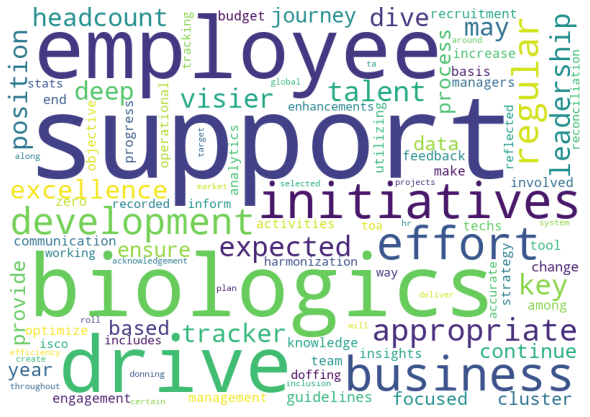

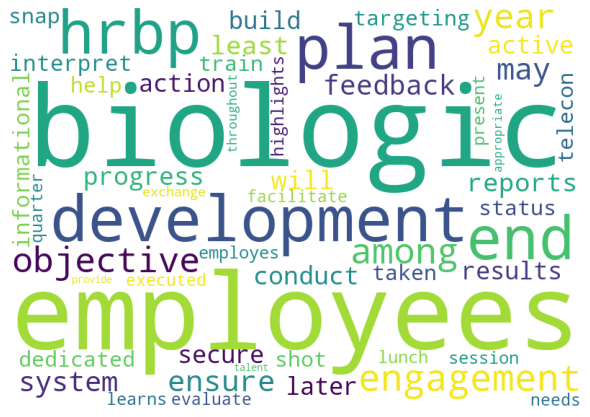

In [42]:
### Top words from LDA
if TopicModelObject.method == 'LDA' or TopicModelObject.method == 'LSI':
    
    lda_class_distribution = TopicModelObject.vec[TopicModelObject.base]
    labels = np.argmax(lda_class_distribution, axis=1)
    

    # To get the top words for each topic, this method only uses LDA, doesn't utilize Bert or K mean clustering
    TopicModelObject.get_top_words_base(top=10)

    for k , cluster_word_distribution in TopicModelObject.get_top_words_base(top=100).items():
        get_wordcloud(TopicModelObject, word_distribution = cluster_word_distribution, topic = k )
# Get top words from autoencoder (LDA + Embeddings) and create word clouds on n grams
else:
    grams = 2
    for ng in range(grams):
        print ("WordClouds for {} grams".format(str(ng+1)))
        for i in range(TopicModelObject.k):

            k_sentences = np.array(sentences)[sentence_label_dict[i]]
            ngram_token_with_frequency = generate_n_gram(k_sentences, n=ng+1, separator = '-' ,
                                        keep_stopwords= False, stem=False, keep_nouns_only=False)
    
            get_wordcloud(TopicModelObject, topic=i, word_count_dict = ngram_token_with_frequency)
    

## 4.2 Visualization: Scatter plot

Visualize the feature vectors of each employee in a 2d/3d space using plotly

In [43]:
import plotly.graph_objects as go
from sklearn import preprocessing

In [44]:
from collections import Counter
#main topics for each cluster
cluster_titles = []

for i in range(TopicModelObject.k):
    k_sentences = np.array(sentences)[sentence_label_dict[i]]
    ngram_token_with_frequency = Counter(generate_n_gram(k_sentences, n=3, separator = '-' ,
                                        keep_stopwords= True, stem=False, keep_nouns_only=False))
    
    
    cluster_title = ', '.join([key for key, value in ngram_token_with_frequency.most_common(6)])
    
    cluster_titles.append(cluster_title)
cluster_titles

['will-be-sought, the-ta-function, ta-function-change, of-the-business, on-time-and, and-rolled-out',
 'engagement-interpret-results, interpret-results-help, results-help-build, help-build-plans, build-plans-secure, plans-secure-feedback']

In [45]:
np_sentences = np.array(sentences)

In [50]:
fig = go.Figure()


for i, cl in enumerate(range(k)):
    
    cluster_df = averaged_employee_features[averaged_employee_features.cluster==cl]
    #plot all the employees belonging to a cluster using a new trace. 
    features = np.stack(cluster_df['feature_vector_2d'].to_numpy())

    employee_titles = []
    # constructing hover text (all objectives belonging to that employee) 
    for emp in cluster_df.index.values:
        
        emp_indices = employee_objective_indices[emp]
        employee_title = '. '.join([objective for objective in np_sentences[emp_indices]])
    
        employee_titles.append(emp + ': ' + employee_title)
        
    fig.add_trace(go.Scattergl(
      x=features[:, 0],
      y=features[:, 1],
      mode='markers',
      showlegend=True,
      text = employee_titles,
      marker=dict(size=8, color=i),
      name="cluster_"+str(cl+1) +": " + cluster_titles[cl]
      ))



fig.update_layout(title='Distribution of employees over clusters in 2d space', legend=dict(
        x=0.6,
        y=1.4,
        traceorder='normal',
        font=dict(
            size=10)))
fig.show()


In [51]:
fig = go.Figure()


for i, cl in enumerate(range(k)):
    cluster_df = averaged_employee_features[averaged_employee_features.cluster==cl]

    #plot all the employees belonging to a cluster using a new trace. 
    features = np.stack(cluster_df['feature_vector_2d'].to_numpy())
    
    #normalize the features between 0 and 1
    features_normed = preprocessing.normalize(features)
    
    employee_titles = []
    # constructing hover text (all objectives belonging to that employee) 
    for emp in cluster_df.index.values:
        
        emp_indices = employee_objective_indices[emp]
        employee_title = '. '.join([objective for objective in np_sentences[emp_indices]])
    
        employee_titles.append(emp + ': ' + employee_title)


    fig.add_trace(go.Scattergl(
      x=features_normed[:, 0],
      y=features_normed[:, 1],
      mode='markers',
      showlegend=True,
      text = employee_titles,
      marker=dict(size=8, color=i),
      name="cluster_"+str(cl+1) +": " + cluster_titles[cl]
    ))



fig.update_layout(title='Distribution of employees over clusters in 2d space - Normalized', legend=dict(
        x=0.6,
        y=1.4,
        traceorder='normal',
        font=dict(
            size=10)))
fig.show()

In [52]:
fig = go.Figure()
for i , cl in enumerate(range(k)):
    
    cluster_df = averaged_employee_features[averaged_employee_features.cluster==cl]

    #plot all the employees belonging to a cluster using a new trace. 
    features = np.stack(cluster_df['feature_vector_3d'].to_numpy())
    
    employee_titles = []
    # constructing hover text (all objectives belonging to that employee) 
    for emp in cluster_df.index.values:
        
        emp_indices = employee_objective_indices[emp]
        employee_title = '. '.join([objective for objective in np_sentences[emp_indices]])
    
        employee_titles.append(emp + ': ' + employee_title)


    fig.add_trace(go.Scatter3d(
      x=features[:, 0],
      y=features[:, 1],
      z=features[:, 2],
      mode='markers',
      showlegend=True,
      text = employee_titles,
      marker=dict(size=3, color=i),
      name="cluster_"+str(cl+1) +": " + cluster_titles[cl]
    ))

fig.update_layout(title='Distribution of employees over clusters in 3d Space', legend=dict(
        x=0.6,
        y=1.4,
        traceorder='normal',
        font=dict(
            size=10)))
fig.show()

In [53]:
fig = go.Figure()

for i, cl in enumerate(range(k)):
    cluster_df = averaged_employee_features[averaged_employee_features.cluster==cl]

    #plot all the employees belonging to a cluster using a new trace. 
    features = np.stack(cluster_df['feature_vector_3d'].to_numpy())
    
    #normalize the features between 0 and 1
    features_normed = preprocessing.normalize(features)
    
    employee_titles = []
    # constructing hover text (all objectives belonging to that employee) 
    for emp in cluster_df.index.values:
        
        emp_indices = employee_objective_indices[emp]
        employee_title = '. '.join([objective for objective in np_sentences[emp_indices]])
    
        employee_titles.append(emp + ': ' + employee_title)


    fig.add_trace(go.Scatter3d(
      x=features_normed[:, 0],
      y=features_normed[:, 1],
      z=features_normed[:, 2],
      mode='markers',
      showlegend=True,
      text = employee_titles,
      marker=dict(size=3, color=i),
      name="cluster_"+str(cl+1) +": " + cluster_titles[cl]
    ))

fig.update_layout(title='Distribution of employees over clusters in 3d Space - Normalized', legend=dict(
        x=0.6,
        y=1.4,
        traceorder='normal',
        font=dict(
            size=10)))
fig.show()

### 4.3 pyLDAvis
This visualization only works on LDA results

In [ ]:
import pyLDAvis
from pyLDAvis import gensim as gs

In [ ]:
id2word = corpora.Dictionary(token_lists)
corpus = [id2word.doc2bow(text) for text in token_lists]

In [ ]:
pyLDAvis.enable_notebook()
vis = gs.prepare(TopicModelObject.ldamodel, corpus, id2word)
vis